# DriveSight — Visualisation des détections YOLOv8s

Produit 60 images annotées à partir du split `test`, sans modifier les images originales. Cette étape nécessite les poids `best.pt` de YOLOv8s.

In [1]:
from pathlib import Path
import random
import cv2
import torch
from ultralytics import YOLO
from IPython.display import display, Image


In [2]:
from pathlib import Path
import os
import random
import cv2
import torch
import yaml
import matplotlib.pyplot as plt
from ultralytics import YOLO
from IPython.display import display, Image

REPO = Path(r"C:\Users\Kenza\DriveSight")
DATA_YAML = REPO / "data" / "yolo" / "data.yaml"
RUNS_DIR = REPO / "runs"

YOLOV8_PATH = RUNS_DIR / "bdd_yolov8s" / "weights" / "best.pt"
YOLO11_PATH = RUNS_DIR / "bdd_yolo11s" / "weights" / "best.pt"

TEST_IMAGES_DIR = REPO / "data" / "yolo" / "images" / "test"
OUTPUT_DIR = REPO / "experiments" / "yolo_model_comparison" / "visualizations"

if not REPO.is_dir():
    raise FileNotFoundError(f"Dépôt introuvable : {REPO}")
if not DATA_YAML.is_file():
    raise FileNotFoundError(f"Dataset introuvable : {DATA_YAML}")
if not YOLOV8_PATH.is_file():
    raise FileNotFoundError(f"Poids YOLOv8s absents : {YOLOV8_PATH}")
if not YOLO11_PATH.is_file():
    raise FileNotFoundError(f"Poids YOLO11s absents : {YOLO11_PATH}")
if not TEST_IMAGES_DIR.is_dir():
    raise FileNotFoundError(f"Images de test absentes : {TEST_IMAGES_DIR}")

os.chdir(REPO)

print("Dépôt :", REPO)
print("YOLOv8s trouvé :", YOLOV8_PATH.is_file())
print("YOLO11s trouvé :", YOLO11_PATH.is_file())
print("Images de test :", TEST_IMAGES_DIR)
print("GPU disponible :", torch.cuda.is_available())

Dépôt : C:\Users\Kenza\DriveSight
YOLOv8s trouvé : True
YOLO11s trouvé : True
Images de test : C:\Users\Kenza\DriveSight\data\yolo\images\test
GPU disponible : True


## 1. Vérifier le modèle et les images de test

In [3]:
image_paths = sorted(
    p for p in TEST_IMAGES_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in
    {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

if len(image_paths) < 1:
    raise ValueError("Aucune image de test trouvée.")

random.seed(42)
selected_images = random.sample(image_paths, min(60, len(image_paths)))

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Images disponibles :", len(image_paths))
print("Images sélectionnées :", len(selected_images))
print("Dossier de sortie :", OUTPUT_DIR)

Images disponibles : 375
Images sélectionnées : 60
Dossier de sortie : C:\Users\Kenza\DriveSight\experiments\yolo_model_comparison\visualizations


## 2. Générer les prédictions des deux modèles

In [4]:
model_v8 = YOLO(str(YOLOV8_PATH))
model_11 = YOLO(str(YOLO11_PATH))

for index, image_path in enumerate(selected_images, start=1):
    image = cv2.imread(str(image_path))

    if image is None:
        print("Image ignorée :", image_path.name)
        continue

    # Prédictions sur la même image
    pred_v8 = model_v8.predict(
        source=image,
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    pred_11 = model_11.predict(
        source=image,
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    # Images avec boîtes de détection
    annotated_v8 = pred_v8.plot()
    annotated_11 = pred_11.plot()

    # Enregistrer les deux résultats
    cv2.imwrite(
        str(OUTPUT_DIR / f"{index:03d}_yolov8s_{image_path.stem}.jpg"),
        annotated_v8
    )
    cv2.imwrite(
        str(OUTPUT_DIR / f"{index:03d}_yolo11s_{image_path.stem}.jpg"),
        annotated_11
    )

print("Visualisation terminée.")
print("Résultats enregistrés dans :", OUTPUT_DIR)

Visualisation terminée.
Résultats enregistrés dans : C:\Users\Kenza\DriveSight\experiments\yolo_model_comparison\visualizations


## 3. Afficher les deux résultats côte à côte

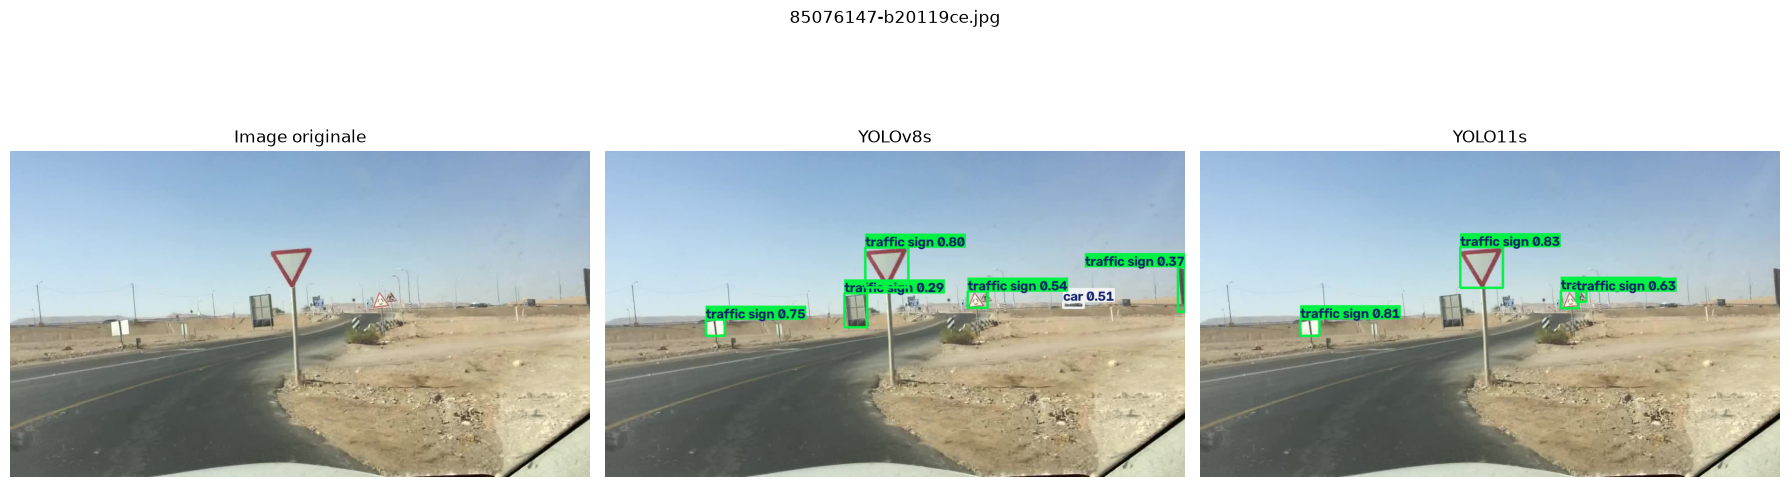

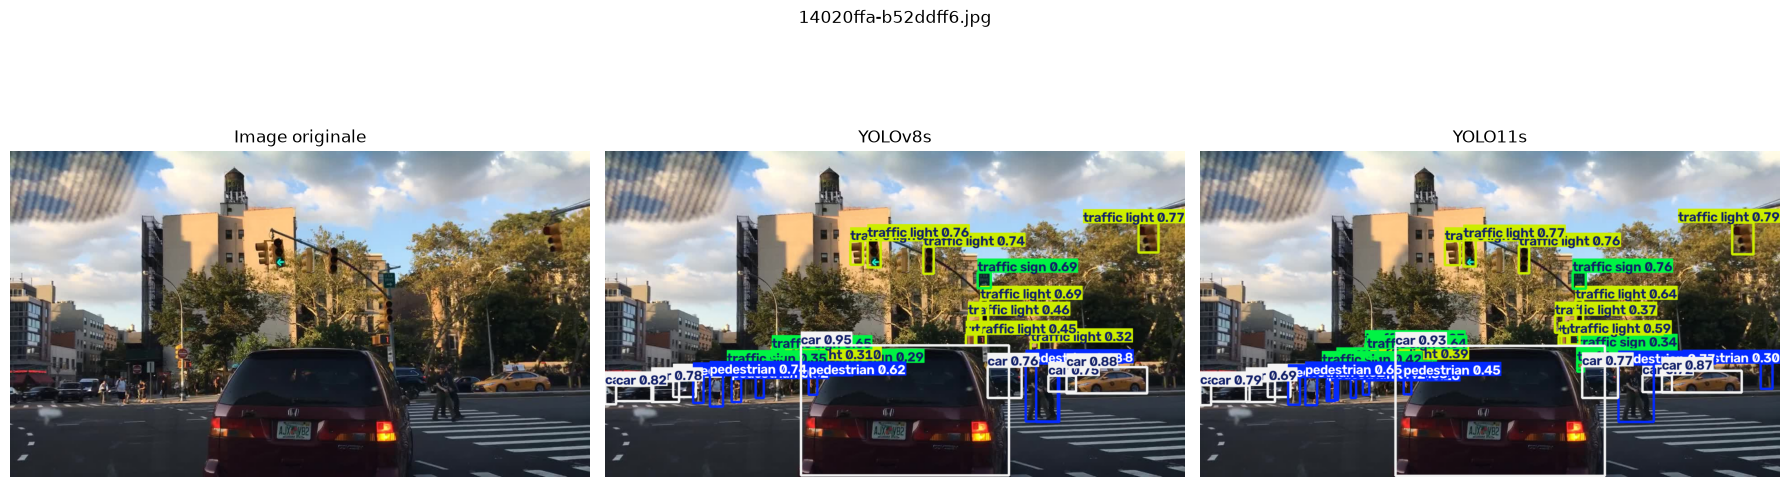

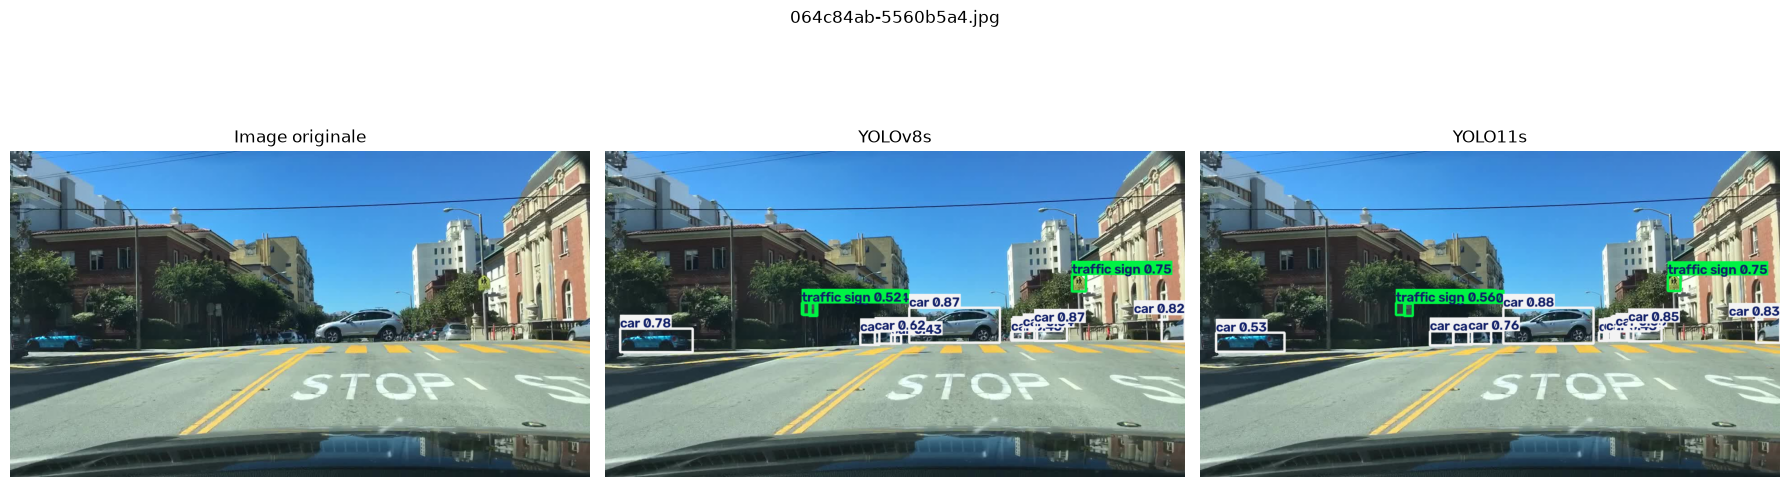

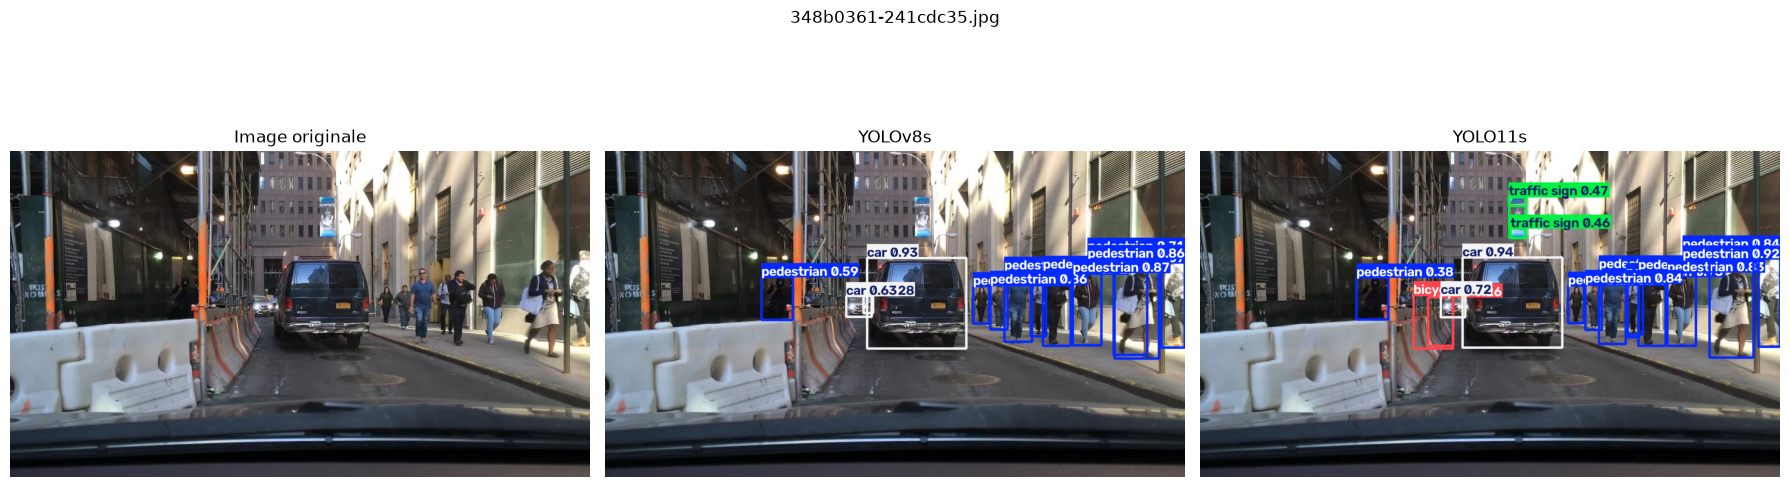

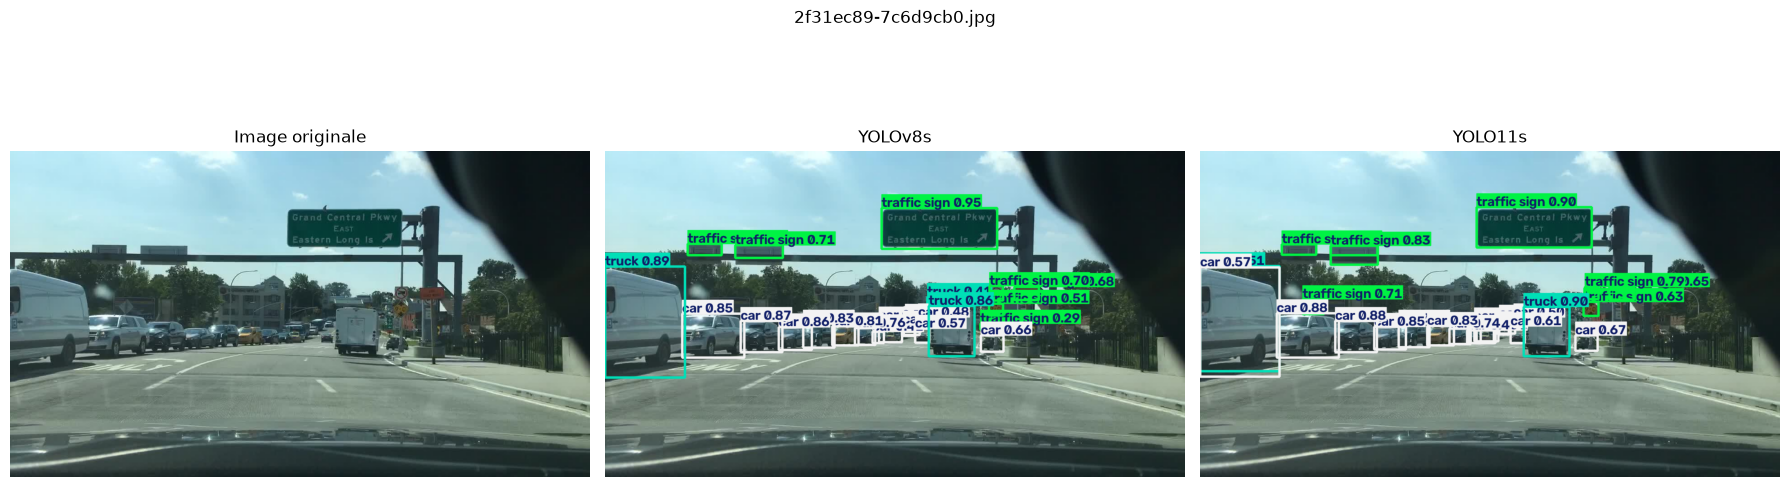

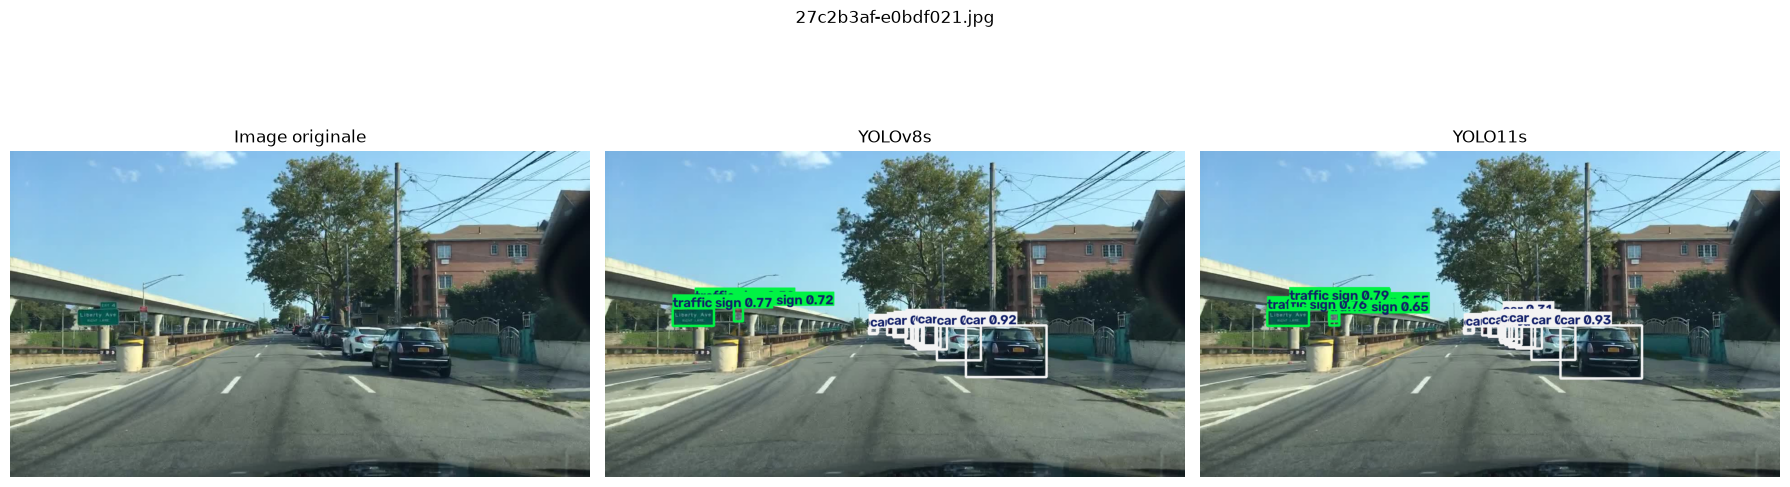

In [5]:
import matplotlib.pyplot as plt

for index in range(min(6, len(selected_images))):
    image_path = selected_images[index]

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    pred_v8 = model_v8.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0].plot()

    pred_11 = model_11.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0].plot()

    pred_v8 = cv2.cvtColor(pred_v8, cv2.COLOR_BGR2RGB)
    pred_11 = cv2.cvtColor(pred_11, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(image)
    axes[0].set_title("Image originale")

    axes[1].imshow(pred_v8)
    axes[1].set_title("YOLOv8s")

    axes[2].imshow(pred_11)
    axes[2].set_title("YOLO11s")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(image_path.name)
    plt.tight_layout()
    plt.show()